# Vehicle Detection in Road Images Using KITTI

This notebook contains the workflow for dataset access, exploratory data analysis (EDA), preprocessing, YOLO training, validation, testing, and error analysis.

## Environment Setup
Install the project dependencies and import the libraries used throughout the notebook.

In [2]:
%pip install -r ../requirements.txt

You should consider upgrading via the '/Users/rogelio/Documents/University_of_San_Diego/AAI_521/final_project/vehicle-detection-cnn/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
from collections import Counter
import shutil
import ssl
import urllib.request
import zipfile

import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

## KITTI Dataset Access and Exploratory Data Analysis

The project uses the Ultralytics formatted KITTI 2D object detection dataset. It contains 7,481 labeled road images split into 5,985 training images and 1,496 validation images. The eight supplied classes are car, van, truck, pedestrian, person_sitting, cyclist, tram, and misc.

The purpose of this EDA is to verify that the dataset is usable for deep learning and to identify preprocessing decisions before training. We will examine:

- dataset and annotation completeness
- image dimensions and aspect ratios
- class balance
- number of objects per image
- bounding-box size and shape
- small-object prevalence
- invalid or suspicious annotations
- representative annotated images

The vehicle specific modeling phase will later focus on **car, van, and truck**.

### Download the KITTI YOLO Dataset

Downloads the KITTI YOLO Dataset and stores all data under the datatsets directory.

In [ ]:
DATA_ROOT = Path("./datasets")
KITTI_DIR = DATA_ROOT  # The archive extracts images, labels, and kitti.yaml here
KITTI_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip"
ZIP_PATH = DATA_ROOT / "kitti.zip"
REQUIRED_PATHS = (
    KITTI_DIR / "images" / "train",
    KITTI_DIR / "images" / "val",
    KITTI_DIR / "labels" / "train",
    KITTI_DIR / "labels" / "val",
    KITTI_DIR / "kitti.yaml",
)

DATA_ROOT.mkdir(parents=True, exist_ok=True)
dataset_ready = all(path.exists() for path in REQUIRED_PATHS)

if not dataset_ready:
    print("KITTI dataset not found. Downloading...")
    if not ZIP_PATH.exists():
        ssl_context = ssl.create_default_context(cafile=certifi.where())
        partial_path = ZIP_PATH.with_suffix(".zip.part")
        try:
            with urllib.request.urlopen(KITTI_URL, context=ssl_context) as response:
                with partial_path.open("wb") as output_file:
                    shutil.copyfileobj(response, output_file)
            partial_path.replace(ZIP_PATH)
        except Exception:
            partial_path.unlink(missing_ok=True)
            raise
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_ROOT)
else:
    print("KITTI dataset already exists.")

missing_paths = [path for path in REQUIRED_PATHS if not path.exists()]
if missing_paths:
    missing = ", ".join(str(path) for path in missing_paths)
    raise FileNotFoundError(f"KITTI extraction is incomplete; missing: {missing}")

print(f"KITTI directory: {KITTI_DIR.resolve()}")

KITTI dataset already exists.
KITTI directory: /Users/rogelio/Documents/University_of_San_Diego/AAI_521/final_project/vehicle-detection-cnn/notebooks/datasets


### Define Classes and Verify Dataset Structure

YOLO labels use normalized bounding-box values in the format:

`class_id x_center y_center width height`

All four bounding-box coordinates should normally fall between 0 and 1.

In [10]:
CLASS_NAMES = {
    0: "car",
    1: "van",
    2: "truck",
    3: "pedestrian",
    4: "person_sitting",
    5: "cyclist",
    6: "tram",
    7: "misc",
}

VEHICLE_CLASS_IDS = {0, 1, 2}

for split in ["train", "val"]:
    image_dir = KITTI_DIR / "images" / split
    label_dir = KITTI_DIR / "labels" / split

    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Missing images or labels for split: {split}")

    image_files = sorted(image_dir.glob("*"))
    label_files = sorted(label_dir.glob("*.txt"))

    print(
        f"{split:>5}: "
        f"{len(image_files):,} images | "
        f"{len(label_files):,} label files"
    )

train: 5,985 images | 5,985 label files
  val: 1,496 images | 1,496 label files


### Check for Missing Labels, Empty Labels, and Unmatched Files

Before modeling, each image should have a corresponding annotation file. Images without objects may legitimately have empty label files, but they should be identified and documented.

In [11]:
quality_rows = []

for split in ["train", "val"]:
    image_dir = KITTI_DIR / "images" / split
    label_dir = KITTI_DIR / "labels" / split

    image_files = sorted([p for p in image_dir.iterdir() if p.is_file()])
    label_files = sorted(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in image_files}
    label_stems = {p.stem for p in label_files}

    missing_label_stems = sorted(image_stems - label_stems)
    orphan_label_stems = sorted(label_stems - image_stems)
    empty_label_files = [p for p in label_files if p.stat().st_size == 0]

    quality_rows.append({
        "split": split,
        "images": len(image_files),
        "label_files": len(label_files),
        "missing_labels": len(missing_label_stems),
        "orphan_labels": len(orphan_label_stems),
        "empty_labels": len(empty_label_files),
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

,split,images,label_files,missing_labels,orphan_labels,empty_labels
0,train,5985,5985,0,0,0
1,val,1496,1496,0,0,0


### Measure Image Dimensions

Object detectors resize images during training, but first we should understand the original image sizes and aspect ratios. This helps document how much resizing or letterboxing will occur.

In [12]:
image_rows = []

for split in ["train", "val"]:
    image_dir = KITTI_DIR / "images" / split

    for image_path in sorted([p for p in image_dir.iterdir() if p.is_file()]):
        with Image.open(image_path) as img:
            width, height = img.size
            image_rows.append({
                "split": split,
                "image": image_path.name,
                "width": width,
                "height": height,
                "aspect_ratio": width / height,
            })

images_df = pd.DataFrame(image_rows)

print(f"Total images inspected: {len(images_df):,}")
display(images_df[["width", "height", "aspect_ratio"]].describe().round(3))

print("\nMost common image dimensions:")
display(
    images_df.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(10)
)

Total images inspected: 7,481


,width,height,aspect_ratio
count,7481.000,7481.000,7481.000
mean,1239.916,374.477,3.311
std,5.460,1.545,0.002
min,1224.000,370.000,3.301
25%,1242.000,375.000,3.312
50%,1242.000,375.000,3.312
75%,1242.000,375.000,3.312
max,1242.000,376.000,3.312



Most common image dimensions:


,width,height,image_count
3,1242,375,6057
0,1224,370,770
1,1238,374,358
2,1241,376,296


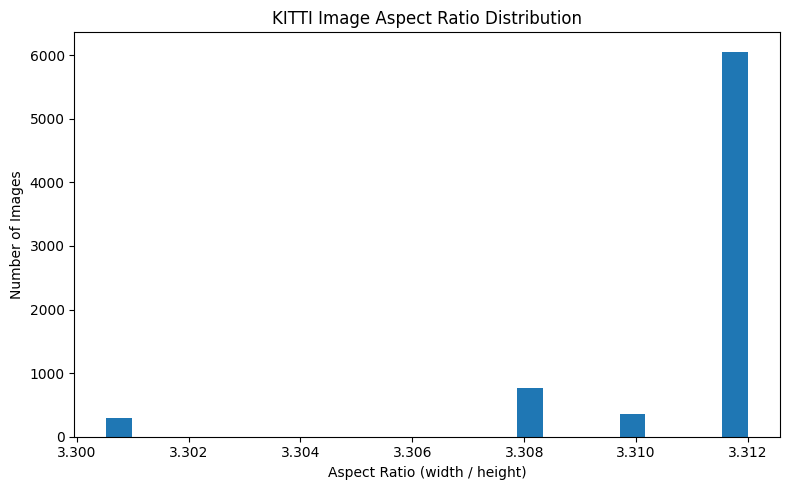

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(images_df["aspect_ratio"], bins=25)
plt.xlabel("Aspect Ratio (width / height)")
plt.ylabel("Number of Images")
plt.title("KITTI Image Aspect Ratio Distribution")
plt.tight_layout()
plt.show()

### Parse All YOLO Annotations

The following cell converts every YOLO annotation into a tabular structure for EDA. Pixel level bounding-box dimensions are calculated using the original image dimensions.

In [17]:
image_lookup = images_df.set_index(["split", "image"])[["width", "height"]].to_dict("index")

annotation_rows = []
invalid_rows = []
objects_per_image = Counter()

for split in ["train", "val"]:
    label_dir = KITTI_DIR / "labels" / split

    for label_path in sorted(label_dir.glob("*.txt")):
        image_name = None
        png_name = f"{label_path.stem}.png"
        jpg_name = f"{label_path.stem}.jpg"

        if (split, png_name) in image_lookup:
            image_name = png_name
        elif (split, jpg_name) in image_lookup:
            image_name = jpg_name
        else:
            matches = images_df[
                (images_df["split"] == split) &
                (images_df["image"].str.rsplit(".", n=1).str[0] == label_path.stem)
            ]
            if not matches.empty:
                image_name = matches.iloc[0]["image"]

        if image_name is None:
            continue

        img_w = image_lookup[(split, image_name)]["width"]
        img_h = image_lookup[(split, image_name)]["height"]

        lines = label_path.read_text().strip().splitlines()
        objects_per_image[(split, image_name)] = len(lines)

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()

            if len(parts) != 5:
                invalid_rows.append({
                    "split": split,
                    "label_file": label_path.name,
                    "line": line_number,
                    "reason": "Expected 5 values",
                    "raw": line,
                })
                continue

            try:
                class_id = int(float(parts[0]))
                x_center, y_center, box_w, box_h = map(float, parts[1:])
            except ValueError:
                invalid_rows.append({
                    "split": split,
                    "label_file": label_path.name,
                    "line": line_number,
                    "reason": "Non-numeric value",
                    "raw": line,
                })
                continue

            issues = []
            if class_id not in CLASS_NAMES:
                issues.append("Unknown class")
            if not (0 <= x_center <= 1 and 0 <= y_center <= 1):
                issues.append("Center outside [0,1]")
            if not (0 < box_w <= 1 and 0 < box_h <= 1):
                issues.append("Invalid width/height")
            if x_center - box_w / 2 < -1e-6 or x_center + box_w / 2 > 1 + 1e-6:
                issues.append("Box crosses horizontal boundary")
            if y_center - box_h / 2 < -1e-6 or y_center + box_h / 2 > 1 + 1e-6:
                issues.append("Box crosses vertical boundary")

            if issues:
                invalid_rows.append({
                    "split": split,
                    "label_file": label_path.name,
                    "line": line_number,
                    "reason": "; ".join(issues),
                    "raw": line,
                })

            annotation_rows.append({
                "split": split,
                "image": image_name,
                "class_id": class_id,
                "class_name": CLASS_NAMES.get(class_id, "unknown"),
                "x_center": x_center,
                "y_center": y_center,
                "box_width_norm": box_w,
                "box_height_norm": box_h,
                "bbox_area_relative": box_w * box_h,
                "bbox_aspect_ratio": box_w / box_h if box_h > 0 else np.nan,
                "bbox_width_px": box_w * img_w,
                "bbox_height_px": box_h * img_h,
                "bbox_area_px": box_w * img_w * box_h * img_h,
            })

annotations_df = pd.DataFrame(annotation_rows)
invalid_df = pd.DataFrame(invalid_rows)

print(f"Total annotated objects: {len(annotations_df):,}")
print(f"Potentially invalid annotation rows: {len(invalid_df):,}")

if not invalid_df.empty:
    display(invalid_df.head(20))

Total annotated objects: 40,570
Potentially invalid annotation rows: 0


### Class Distribution

Class imbalance can affect model performance. This analysis shows how frequently each KITTI class appears and how much of the dataset is represented by the three vehicle classes selected for this project.

,class_name,object_count,percent
0,car,28742,70.85
1,van,2914,7.18
2,truck,1094,2.70
3,pedestrian,4487,11.06
4,person_sitting,222,0.55
5,cyclist,1627,4.01
6,tram,511,1.26
7,misc,973,2.40


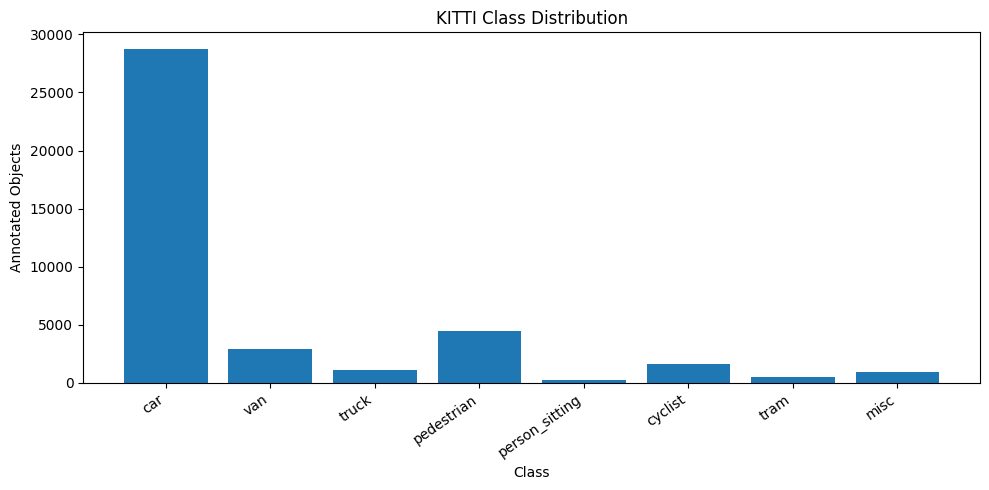

Car, van, and truck annotations: 32,750 (80.7% of all annotated objects)


In [18]:
class_counts = (
    annotations_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES.values(), fill_value=0)
)

class_summary = class_counts.rename("object_count").reset_index()
class_summary.columns = ["class_name", "object_count"]
class_summary["percent"] = (
    class_summary["object_count"] / class_summary["object_count"].sum() * 100
).round(2)

display(class_summary)

plt.figure(figsize=(10, 5))
plt.bar(class_summary["class_name"], class_summary["object_count"])
plt.xlabel("Class")
plt.ylabel("Annotated Objects")
plt.title("KITTI Class Distribution")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

vehicle_count = annotations_df["class_id"].isin(VEHICLE_CLASS_IDS).sum()
print(
    f"Car, van, and truck annotations: {vehicle_count:,} "
    f"({vehicle_count / len(annotations_df):.1%} of all annotated objects)"
)

### Objects Per Image

The number of labeled objects per frame is useful for understanding scene complexity and whether the dataset contains both light and dense traffic conditions.

,object_count
count,7481.00
mean,5.42
std,3.74
min,1.00
25%,2.00
50%,5.00
75%,7.00
max,22.00


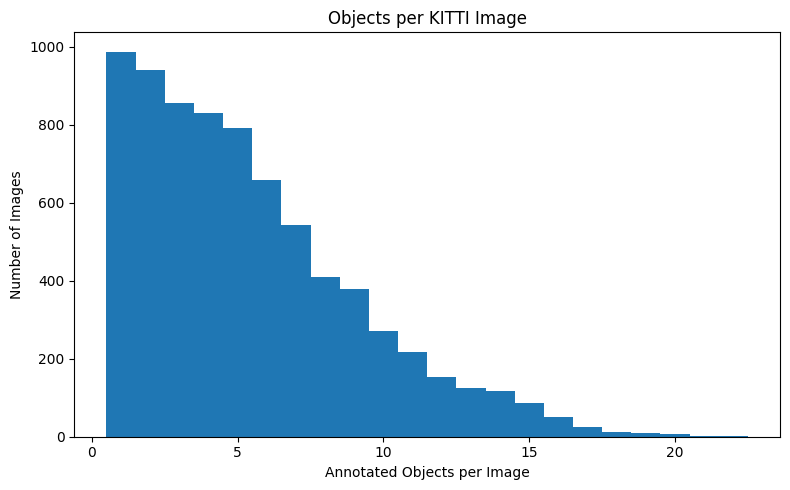

Images with zero retained annotations: 0


In [19]:
count_rows = []

for row in images_df.itertuples(index=False):
    count_rows.append({
        "split": row.split,
        "image": row.image,
        "object_count": objects_per_image.get((row.split, row.image), 0),
    })

objects_per_image_df = pd.DataFrame(count_rows)

display(objects_per_image_df["object_count"].describe().to_frame().round(2))

plt.figure(figsize=(8, 5))
bins = np.arange(
    objects_per_image_df["object_count"].min(),
    objects_per_image_df["object_count"].max() + 2
) - 0.5
plt.hist(objects_per_image_df["object_count"], bins=bins)
plt.xlabel("Annotated Objects per Image")
plt.ylabel("Number of Images")
plt.title("Objects per KITTI Image")
plt.tight_layout()
plt.show()

print(
    "Images with zero retained annotations:",
    int((objects_per_image_df["object_count"] == 0).sum())
)

### Bounding-Box Size Analysis

Small or distant vehicles are typically harder to detect than large nearby vehicles. Relative bounding-box area lets us compare object size independently of the original image dimensions.

,box_width_norm,box_height_norm,bbox_area_relative,bbox_width_px,bbox_height_px
count,40570.0000,40570.0000,40570.0000,40570.0000,40570.0000
mean,0.0817,0.1957,0.0238,101.4325,73.2883
std,0.0713,0.1529,0.0403,88.4945,57.2071
min,0.0001,0.0338,0.0000,0.1089,12.6701
25%,0.0320,0.0885,0.0030,39.6618,33.1601
50%,0.0555,0.1398,0.0077,68.8056,52.3601
75%,0.1060,0.2506,0.0242,131.5974,93.8780
max,0.4681,1.0000,0.4095,581.4199,376.0000


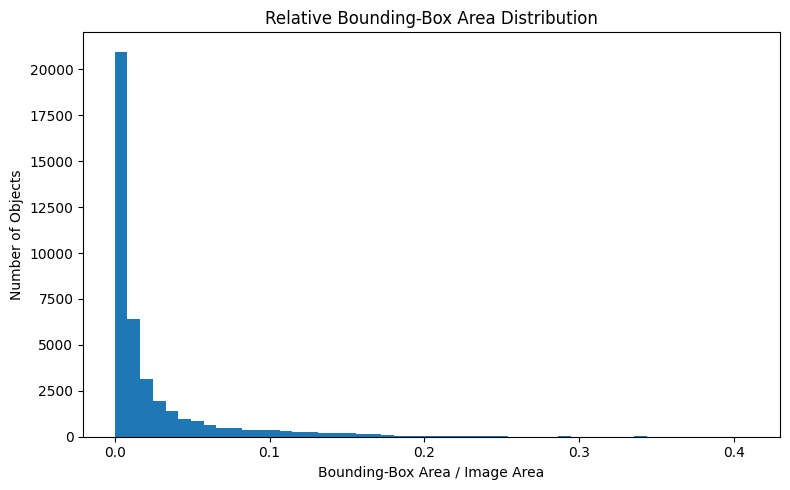

eda_size_group,small (<1%),medium (1-5%),large (>5%)
class_name,,,
car,55.7,29.0,15.3
cyclist,69.2,22.9,7.9
misc,60.4,28.1,11.5
pedestrian,60.7,35.4,4.0
person_sitting,34.7,58.1,7.2
tram,41.7,31.5,26.8
truck,60.5,24.6,14.9
van,53.8,29.4,16.8


In [20]:
display(
    annotations_df[
        [
            "box_width_norm",
            "box_height_norm",
            "bbox_area_relative",
            "bbox_width_px",
            "bbox_height_px",
        ]
    ].describe().round(4)
)

plt.figure(figsize=(8, 5))
plt.hist(annotations_df["bbox_area_relative"], bins=50)
plt.xlabel("Bounding-Box Area / Image Area")
plt.ylabel("Number of Objects")
plt.title("Relative Bounding-Box Area Distribution")
plt.tight_layout()
plt.show()

annotations_df["eda_size_group"] = pd.cut(
    annotations_df["bbox_area_relative"],
    bins=[-np.inf, 0.01, 0.05, np.inf],
    labels=["small (<1%)", "medium (1-5%)", "large (>5%)"],
)

size_by_class = pd.crosstab(
    annotations_df["class_name"],
    annotations_df["eda_size_group"],
    normalize="index"
).mul(100).round(1)

display(size_by_class)

### Vehicle Specific EDA

Because the final model will focus on cars, vans, and trucks, this section compares those classes directly.

,objects,median_width_px,median_height_px,median_relative_area
class_name,,,,
car,28742,79.685,46.990,0.008
van,2914,75.720,52.980,0.009
truck,1094,60.905,59.295,0.008


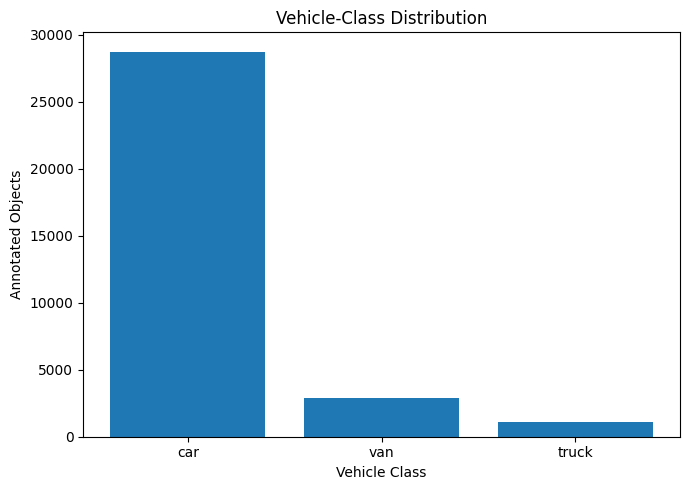

In [21]:
vehicle_df = annotations_df[
    annotations_df["class_id"].isin(VEHICLE_CLASS_IDS)
].copy()

vehicle_summary = (
    vehicle_df.groupby("class_name")
    .agg(
        objects=("class_name", "size"),
        median_width_px=("bbox_width_px", "median"),
        median_height_px=("bbox_height_px", "median"),
        median_relative_area=("bbox_area_relative", "median"),
    )
    .sort_values("objects", ascending=False)
)

display(vehicle_summary.round(3))

vehicle_counts = vehicle_df["class_name"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(vehicle_counts.index, vehicle_counts.values)
plt.xlabel("Vehicle Class")
plt.ylabel("Annotated Objects")
plt.title("Vehicle-Class Distribution")
plt.tight_layout()
plt.show()

### Visualize Annotated Images

Visual inspection is an essential part of image EDA. The function below converts normalized YOLO coordinates back to pixel coordinates and overlays the ground-truth bounding boxes and class labels.

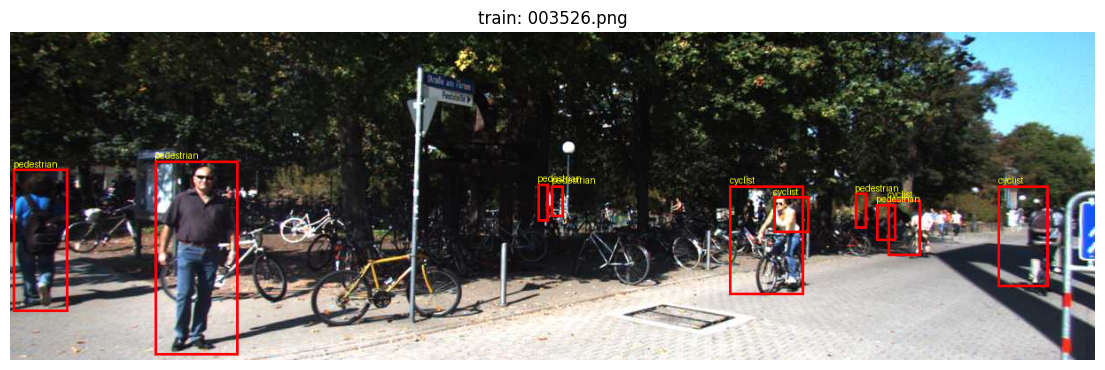

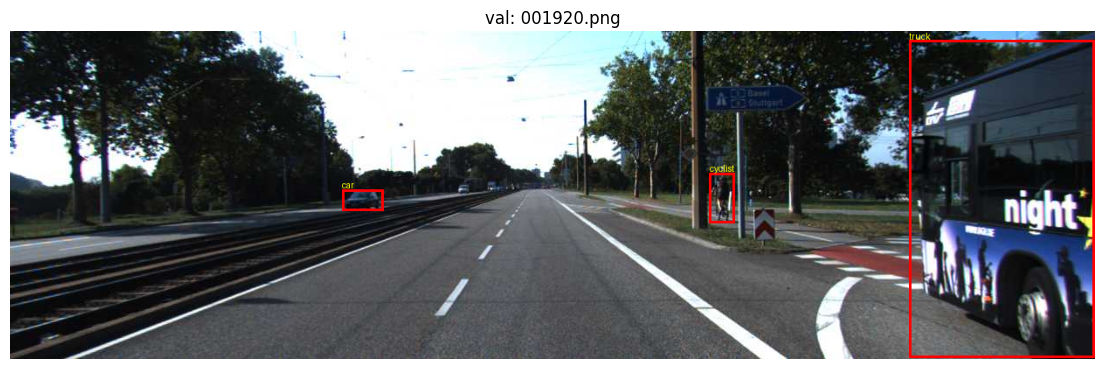

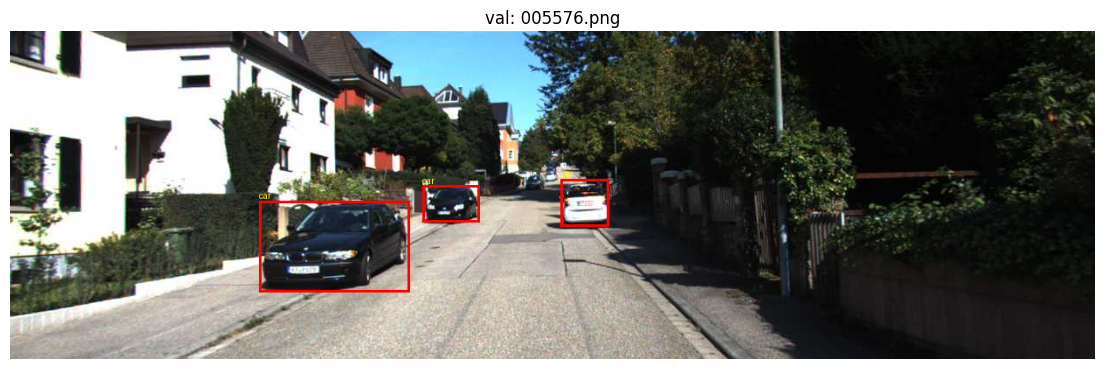

In [22]:
def show_annotated_image(split, image_name, max_boxes=None):
    image_path = KITTI_DIR / "images" / split / image_name
    label_path = KITTI_DIR / "labels" / split / f"{Path(image_name).stem}.txt"

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    if label_path.exists():
        lines = label_path.read_text().strip().splitlines()
        if max_boxes is not None:
            lines = lines[:max_boxes]

        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id = int(float(parts[0]))
            x_center, y_center, box_w, box_h = map(float, parts[1:])

            x1 = (x_center - box_w / 2) * width
            y1 = (y_center - box_h / 2) * height
            x2 = (x_center + box_w / 2) * width
            y2 = (y_center + box_h / 2) * height

            draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
            draw.text(
                (max(0, x1), max(0, y1 - 12)),
                CLASS_NAMES.get(class_id, str(class_id)),
                fill="yellow"
            )

    plt.figure(figsize=(14, 5))
    plt.imshow(image)
    plt.title(f"{split}: {image_name}")
    plt.axis("off")
    plt.show()


sample_rows = images_df.sample(n=3, random_state=42)

for row in sample_rows.itertuples(index=False):
    show_annotated_image(row.split, row.image)

### Inspect Challenging Vehicle Examples

These examples target images containing especially small vehicle boxes. They will be useful later when discussing failure cases and model recall.

,split,image,bbox_area_relative
5064,train,001153.png,0.000023
16667,train,003840.png,0.000046
23531,train,005431.png,0.000401


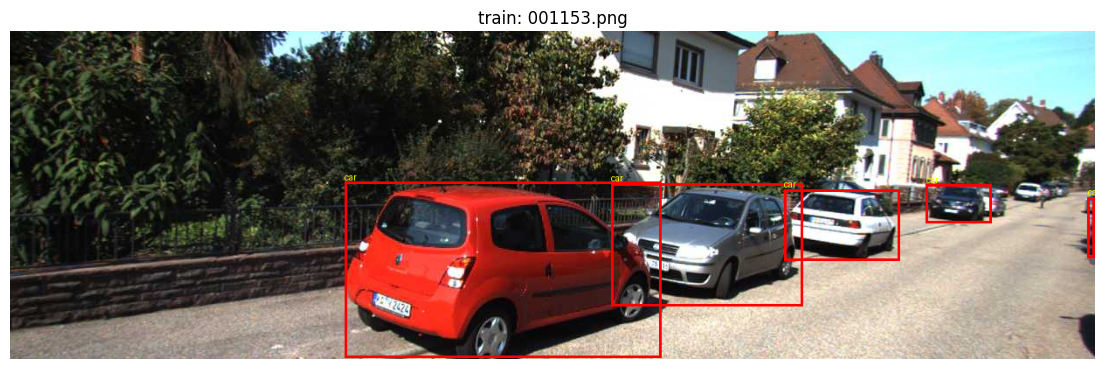

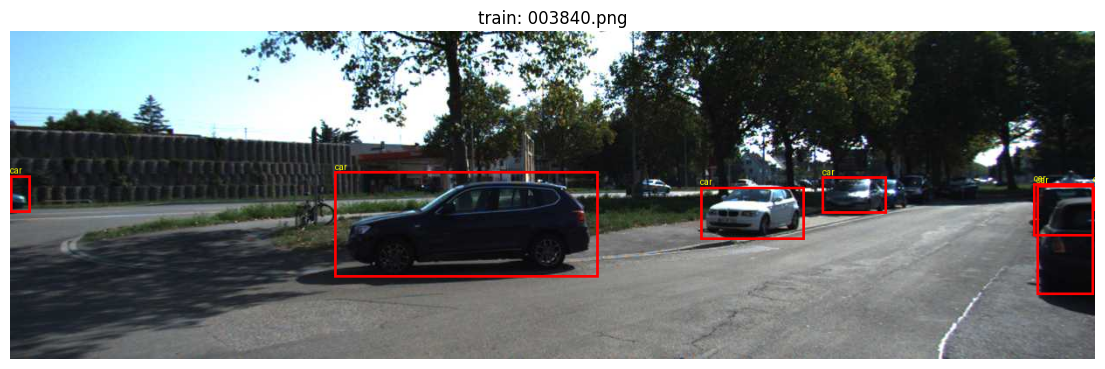

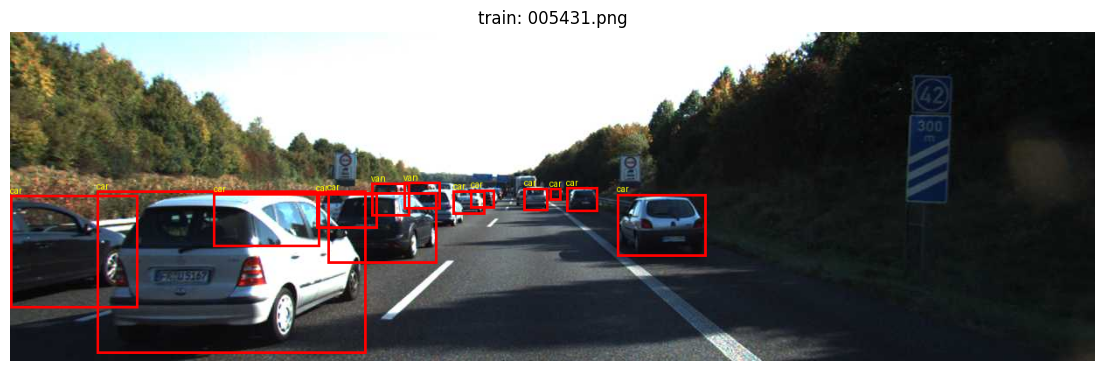

In [23]:
small_vehicle_images = (
    vehicle_df.sort_values("bbox_area_relative")
    [["split", "image", "bbox_area_relative"]]
    .drop_duplicates(["split", "image"])
    .head(3)
)

display(small_vehicle_images)

for row in small_vehicle_images.itertuples(index=False):
    show_annotated_image(row.split, row.image)

### EDA Summary

In [24]:
total_images = len(images_df)
total_objects = len(annotations_df)
most_common_class = annotations_df["class_name"].value_counts().idxmax()
most_common_count = annotations_df["class_name"].value_counts().max()
vehicle_share = len(vehicle_df) / total_objects if total_objects else np.nan
median_objects = objects_per_image_df["object_count"].median()
small_share = (annotations_df["bbox_area_relative"] < 0.01).mean()
unique_dimensions = images_df[["width", "height"]].drop_duplicates().shape[0]
missing_labels = int(quality_df["missing_labels"].sum())
empty_labels = int(quality_df["empty_labels"].sum())

print("EDA SUMMARY")
print("-" * 60)
print(f"Images inspected: {total_images:,}")
print(f"Annotated objects: {total_objects:,}")
print(f"Unique image dimensions: {unique_dimensions:,}")
print(
    f"Most common class: {most_common_class} "
    f"({most_common_count:,} objects; {most_common_count / total_objects:.1%})"
)
print(f"Car/van/truck share of annotations: {vehicle_share:.1%}")
print(f"Median annotated objects per image: {median_objects:.1f}")
print(f"Objects occupying <1% of image area: {small_share:.1%}")
print(f"Images missing a label file: {missing_labels:,}")
print(f"Empty label files: {empty_labels:,}")
print(f"Potentially invalid annotation rows: {len(invalid_df):,}")

print("\nPREPROCESSING IMPLICATIONS")
print("-" * 60)
print("1. Preserve class-balance statistics when creating the train/validation/test split.")
print("2. Convert the project to the selected vehicle classes: car, van, and truck.")
print("3. Use resizing/letterboxing suitable for YOLO while preserving aspect ratio.")
print("4. Retain small-object examples so evaluation reflects distant vehicles.")
print("5. Handle any missing, empty, or invalid labels identified above before training.")

EDA SUMMARY
------------------------------------------------------------
Images inspected: 7,481
Annotated objects: 40,570
Unique image dimensions: 4
Most common class: car (28,742 objects; 70.8%)
Car/van/truck share of annotations: 80.7%
Median annotated objects per image: 5.0
Objects occupying <1% of image area: 56.6%
Images missing a label file: 0
Empty label files: 0
Potentially invalid annotation rows: 0

PREPROCESSING IMPLICATIONS
------------------------------------------------------------
1. Preserve class-balance statistics when creating the train/validation/test split.
2. Convert the project to the selected vehicle classes: car, van, and truck.
3. Use resizing/letterboxing suitable for YOLO while preserving aspect ratio.
4. Retain small-object examples so evaluation reflects distant vehicles.
5. Handle any missing, empty, or invalid labels identified above before training.


## Preprocessing

Creates the YOLO dataset using only **car, van, and truck** annotations. The original KITTI training split is retained for training, while the original validation split is divided evenly into validation and held out test sets using a fixed random seed. Splitting within class presence strata keeps cars, vans, trucks, and negative images represented in both evaluation sets.

Images without a retained vehicle annotation are intentionally preserved with empty YOLO label files. These negative examples help measure and reduce false positive vehicle detections. Images are hard linked when the filesystem supports it, avoiding a second full copy of the KITTI images.

In [26]:
import os
import random
from collections import defaultdict

import yaml

# Reproducible preprocessing configuration
SPLIT_SEED = 42
SOURCE_TO_VEHICLE_CLASS = {0: 0, 1: 1, 2: 2}
VEHICLE_NAMES = {0: "car", 1: "van", 2: "truck"}

working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "notebooks" else working_dir
VEHICLE_DATASET_DIR = PROJECT_ROOT / "data" / "kitti_vehicle"
VEHICLE_YAML_PATH = VEHICLE_DATASET_DIR / "kitti_vehicle.yaml"


def parse_vehicle_labels(label_path):
    """Validate a KITTI YOLO label file and retain car, van, and truck rows."""
    retained = []

    for line_number, line in enumerate(label_path.read_text().splitlines(), start=1):
        if not line.strip():
            continue

        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f"{label_path}:{line_number} must contain 5 values")

        class_value, *coordinate_values = parts
        class_id = int(float(class_value))
        coordinates = [float(value) for value in coordinate_values]
        x_center, y_center, box_width, box_height = coordinates

        if not (0 <= x_center <= 1 and 0 <= y_center <= 1):
            raise ValueError(f"{label_path}:{line_number} has a center outside [0, 1]")
        if not (0 < box_width <= 1 and 0 < box_height <= 1):
            raise ValueError(f"{label_path}:{line_number} has an invalid width or height")
        if x_center - box_width / 2 < -1e-6 or x_center + box_width / 2 > 1 + 1e-6:
            raise ValueError(f"{label_path}:{line_number} crosses the horizontal boundary")
        if y_center - box_height / 2 < -1e-6 or y_center + box_height / 2 > 1 + 1e-6:
            raise ValueError(f"{label_path}:{line_number} crosses the vertical boundary")

        if class_id in SOURCE_TO_VEHICLE_CLASS:
            new_class_id = SOURCE_TO_VEHICLE_CLASS[class_id]
            retained.append((new_class_id, coordinates))

    return retained


def vehicle_presence_stratum(retained_labels):
    """Prioritize rarer classes when assigning an image-level split stratum."""
    present_classes = {class_id for class_id, _ in retained_labels}
    if 2 in present_classes:
        return "truck"
    if 1 in present_classes:
        return "van"
    if 0 in present_classes:
        return "car"
    return "negative"


# Keep the original training split and divide the original validation split in half.
preprocessing_records = []
validation_strata = defaultdict(list)

for source_split in ["train", "val"]:
    image_dir = KITTI_DIR / "images" / source_split
    label_dir = KITTI_DIR / "labels" / source_split

    for image_path in sorted(path for path in image_dir.iterdir() if path.is_file()):
        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.exists():
            raise FileNotFoundError(f"Missing label file for {image_path}")

        retained_labels = parse_vehicle_labels(label_path)
        record = {
            "source_split": source_split,
            "image": image_path.name,
            "image_path": image_path,
            "label_path": label_path,
            "retained_labels": retained_labels,
            "stratum": vehicle_presence_stratum(retained_labels),
        }

        if source_split == "train":
            record["split"] = "train"
            preprocessing_records.append(record)
        else:
            validation_strata[record["stratum"]].append(record)

# Allocate exactly half of the 1,496 original validation images to validation.
rng = random.Random(SPLIT_SEED)
validation_target = sum(len(records) for records in validation_strata.values()) // 2
validation_counts = {
    stratum: len(records) // 2
    for stratum, records in validation_strata.items()
}
remaining_slots = validation_target - sum(validation_counts.values())

# Give any odd-image remainder to the largest odd-sized strata first.
remainder_order = sorted(
    validation_strata,
    key=lambda stratum: (
        len(validation_strata[stratum]) % 2,
        len(validation_strata[stratum]),
        stratum,
    ),
    reverse=True,
)
for stratum in remainder_order[:remaining_slots]:
    validation_counts[stratum] += 1

for stratum, records in sorted(validation_strata.items()):
    rng.shuffle(records)
    validation_count = validation_counts[stratum]

    for index, record in enumerate(records):
        record["split"] = "val" if index < validation_count else "test"
        preprocessing_records.append(record)

# Image names are unique across the supplied KITTI train and validation splits.
image_names = [record["image"] for record in preprocessing_records]
if len(image_names) != len(set(image_names)):
    raise ValueError("Duplicate image names would cause leakage or overwritten files")

split_assignment_df = pd.DataFrame(
    {
        "source_split": record["source_split"],
        "split": record["split"],
        "image": record["image"],
        "stratum": record["stratum"],
        "vehicle_objects": len(record["retained_labels"]),
    }
    for record in preprocessing_records
).sort_values(["split", "image"]).reset_index(drop=True)

display(pd.crosstab(split_assignment_df["split"], split_assignment_df["stratum"]))
print(f"Total images assigned: {len(split_assignment_df):,}")

stratum,car,negative,truck,van
split,,,,
test,390,77,106,175
train,3197,529,824,1435
val,391,77,106,174


Total images assigned: 7,481


In [ ]:
# Build an idempotent YOLO directory tree.
if VEHICLE_DATASET_DIR.resolve() == KITTI_DIR.resolve():
    raise ValueError("Output directory must be different from the source KITTI directory")

if VEHICLE_DATASET_DIR.exists():
    shutil.rmtree(VEHICLE_DATASET_DIR)

for split in ["train", "val", "test"]:
    (VEHICLE_DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (VEHICLE_DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

hard_linked_images = 0
copied_images = 0
class_counts_by_split = defaultdict(Counter)

for record in preprocessing_records:
    split = record["split"]
    source_image = record["image_path"]
    target_image = VEHICLE_DATASET_DIR / "images" / split / source_image.name
    target_label = VEHICLE_DATASET_DIR / "labels" / split / f"{source_image.stem}.txt"

    try:
        os.link(source_image, target_image)
        hard_linked_images += 1
    except OSError:
        shutil.copy2(source_image, target_image)
        copied_images += 1

    output_lines = []
    for class_id, coordinates in record["retained_labels"]:
        coordinate_text = " ".join(f"{value:.6f}" for value in coordinates)
        output_lines.append(f"{class_id} {coordinate_text}")
        class_counts_by_split[split][class_id] += 1

    target_label.write_text(
        "\n".join(output_lines) + ("\n" if output_lines else "")
    )

# Write a portable split manifest and a generated YAML with an unambiguous path.
manifest_path = VEHICLE_DATASET_DIR / "split_manifest.csv"
split_assignment_df.to_csv(manifest_path, index=False)

dataset_config = {
    "path": str(VEHICLE_DATASET_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": VEHICLE_NAMES,
}
VEHICLE_YAML_PATH.write_text(
    yaml.safe_dump(dataset_config, sort_keys=False)
)

# Verify one to one image/label matching, valid output classes, and split isolation.
split_image_stems = {}
summary_rows = []

for split in ["train", "val", "test"]:
    image_dir = VEHICLE_DATASET_DIR / "images" / split
    label_dir = VEHICLE_DATASET_DIR / "labels" / split
    image_stems = {path.stem for path in image_dir.iterdir() if path.is_file()}
    label_paths = sorted(label_dir.glob("*.txt"))
    label_stems = {path.stem for path in label_paths}

    if image_stems != label_stems:
        raise ValueError(f"Image/label mismatch in {split}")

    split_image_stems[split] = image_stems
    negative_images = 0

    for label_path in label_paths:
        lines = [line for line in label_path.read_text().splitlines() if line.strip()]
        if not lines:
            negative_images += 1

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"{label_path}:{line_number} must contain 5 values")

            class_id = int(parts[0])
            coordinates = [float(value) for value in parts[1:]]
            if class_id not in VEHICLE_NAMES:
                raise ValueError(f"Unexpected class {class_id} in {label_path}")
            if not all(0 <= value <= 1 for value in coordinates):
                raise ValueError(f"Out-of-range coordinate in {label_path}:{line_number}")
            if coordinates[2] <= 0 or coordinates[3] <= 0:
                raise ValueError(f"Non-positive box size in {label_path}:{line_number}")

    counts = class_counts_by_split[split]
    summary_rows.append({
        "split": split,
        "images": len(image_stems),
        "positive_images": len(image_stems) - negative_images,
        "negative_images": negative_images,
        "car_objects": counts[0],
        "van_objects": counts[1],
        "truck_objects": counts[2],
        "total_vehicle_objects": sum(counts.values()),
    })

for left_split, right_split in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = split_image_stems[left_split] & split_image_stems[right_split]
    if overlap:
        raise ValueError(f"Data leakage between {left_split} and {right_split}: {len(overlap)} images")

preprocessing_summary_df = pd.DataFrame(summary_rows)
display(preprocessing_summary_df)

print(f"Images hard-linked: {hard_linked_images:,}")
print(f"Images copied: {copied_images:,}")
print(f"Split manifest: {manifest_path}")
print(f"YOLO dataset YAML: {VEHICLE_YAML_PATH}")
print("Preprocessing validation passed: matched labels, valid classes, and no split leakage.")

,split,images,positive_images,negative_images,car_objects,van_objects,truck_objects,total_vehicle_objects
0,train,5985,5456,529,23026,2359,871,26256
1,val,748,671,77,2871,279,114,3264
2,test,748,671,77,2845,276,109,3230


Images hard-linked: 7,481
Images copied: 0
Split manifest: /Users/rogelio/Documents/University_of_San_Diego/AAI_521/final_project/vehicle-detection-cnn/data/kitti_vehicle/split_manifest.csv
YOLO dataset YAML: /Users/rogelio/Documents/University_of_San_Diego/AAI_521/final_project/vehicle-detection-cnn/data/kitti_vehicle/kitti_vehicle.yaml
Preprocessing validation passed: matched labels, valid classes, and no split leakage.


### Preprocessing Output

The generated dataset contains **5,985 training images, 748 validation images, and 748 held out test images**. The test split remains untouched during model selection and hyperparameter tuning. The validation/test split is stratified by vehicle presence, including a separate negative image stratum, so rare truck and van scenes are represented in both evaluation sets.

Only car, van, and truck annotations are written to the new labels, with class IDs 0, 1, and 2. All 7,481 source images are retained and images containing no selected vehicle class receive an empty label file and act as negative examples. The validation code checks image/label matching, coordinate ranges, class IDs, and pairwise split overlap before training.

Use the generated `kitti_vehicle.yaml` path printed above as the Ultralytics `data` argument. The `split_manifest.csv` file records every image's source split, final split, stratum, and retained vehicle count, making the preprocessing procedure reproducible and auditable.

You only need the dataset YAML path:

```python
DATA_YAML = VEHICLE_DATASET_DIR / "kitti_vehicle.yaml"
```

The YAML already defines all splits:

```yaml
train: images/train
val: images/val
test: images/test
```

Training automatically uses `train` and `val`:

```python
model.train(data=str(DATA_YAML), ...)
```

Final testing explicitly selects `test`:

```python
model.val(data=str(DATA_YAML), split="test")
```

You do not need separate `X_train`, `X_val`, or `X_test` variables. Ultralytics finds matching labels in `labels/train`, `labels/val`, and `labels/test`.

## Modeling
Train baseline, fine-tuned, and augmentation experiments.

## Evaluation and Findings
Compare precision, recall, F1, mAP, and representative failure cases.